<a href="https://colab.research.google.com/github/Safwanach2002/ML/blob/main/Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Mount Google Drive
drive.mount('/content/drive')

# Load Excel dataset
df = pd.read_excel('/content/drive/MyDrive/Naive_Bayes_Dataset.xlsx')

print("Dataset Loaded Successfully!")

Mounted at /content/drive
Dataset Loaded Successfully!


First 10 Records:
   Study_Hours_Per_Day  Attendance_Percent  Assignment_Score_Percent  \
0                    1                  92                        67   
1                    7                  85                        79   
2                    6                  70                        78   
3                    4                  94                        69   
4                    4                  71                        88   
5                    7                  68                        73   
6                    1                  92                        49   
7                    6                  70                        84   
8                    2                  58                        74   
9                    1                  74                        77   

   Previous_Marks_Percent Study_Level Attendance_Level Assignment_Level Result  
0                      87         Low             High           Medium   Pass  
1                      47  

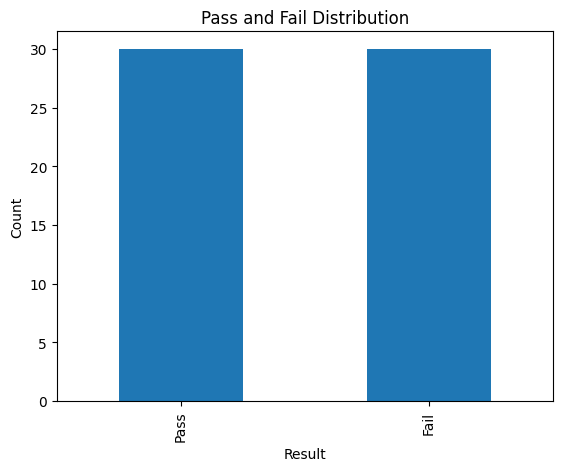


Numerical Features:
['Study_Hours_Per_Day', 'Attendance_Percent', 'Assignment_Score_Percent', 'Previous_Marks_Percent']

Categorical Features:
['Study_Level', 'Attendance_Level', 'Assignment_Level']


In [ ]:
#1.LOAD AND UNDERSTAND THE DATASET

# a) Display first 10 records
print("First 10 Records:")
print(df.head(10))

# b) Display input features and target variable
print("\nInput Features:")
print(df.drop(columns=['Result']).columns.tolist())

print("\nTarget Variable: Result")

# c) Display class distribution
print("\nClass Distribution:")
print(df['Result'].value_counts())

df['Result'].value_counts().plot(kind='bar')
plt.xlabel("Result")
plt.ylabel("Count")
plt.title("Pass and Fail Distribution")
plt.show()

# d) Identify numerical and categorical features
print("\nNumerical Features:")
print(df.drop(columns=['Result']).select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist())

In [ ]:
# 2. BAYES THEOREM AND PROBABILITY CALCULATION

# Select categorical features
cat_cols = df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist()
features = cat_cols[:2]

# a) Calculate prior probability
print("Prior Probability:")
print(df['Result'].value_counts(normalize=True))

# b) Calculate conditional probabilities
for col in features:
    print("\n", col)
    print(pd.crosstab(df[col], df['Result'], normalize='columns'))

# c) Naive Bayes assumption
# Features are conditionally independent.

# d) Create a new student
new_student = {col: df[col].mode()[0] for col in features}
print("\nNew Student:", new_student)

# e) Calculate likelihood and posterior
posterior = {}

for c in df['Result'].unique():
    prob = df['Result'].value_counts(normalize=True)[c]

    for col in features:
        count = ((df[col] == new_student[col]) &
                 (df['Result'] == c)).sum()
        total = (df['Result'] == c).sum()
        prob *= count / total

    posterior[c] = prob

# f) Normalize posterior probability
total = sum(posterior.values())
if total > 0:
    posterior = {c: p/total for c, p in posterior.items()}
    print("\nPosterior Probability:", posterior)

    # g) Predict result
    print("Predicted Result:", max(posterior, key=posterior.get))
else:
    print("Zero probability. Apply Laplace smoothing.")

Prior Probability:
Result
Pass    0.5
Fail    0.5
Name: proportion, dtype: float64

 Study_Level
Result       Fail  Pass
Study_Level            
High          0.3   0.6
Low           0.5   0.1
Medium        0.2   0.3

 Attendance_Level
Result                Fail      Pass
Attendance_Level                    
High              0.233333  0.366667
Low               0.433333  0.200000
Medium            0.333333  0.433333

New Student: {'Study_Level': 'High', 'Attendance_Level': 'Medium'}

Posterior Probability: {'Pass': np.float64(0.7222222222222223), 'Fail': np.float64(0.2777777777777778)}
Predicted Result: Pass


In [ ]:
# 3. LAPLACE SMOOTHING AND COMPLETE NAIVE BAYES WORKING

# a) Identify zero probability
# Zero occurs when a feature value is not found in a class.

# b) Apply Laplace smoothing
for col in features:
    print("\nConditional Probability:", col)
    print(pd.crosstab(df[col], df['Result']))

# c) Calculate probability using Laplace smoothing
posterior = {}

for c in df['Result'].unique():
    prob = (df['Result'].value_counts()[c] / len(df))

    for col in features:
        count = ((df[col] == new_student[col]) &
                 (df['Result'] == c)).sum()

        k = df[col].nunique()
        total = (df['Result'] == c).sum()

        prob *= (count + 1) / (total + k)

    posterior[c] = prob

# d) Normalize posterior probability
total = sum(posterior.values())
posterior = {c: p/total for c, p in posterior.items()}

print("\nPosterior Probabilities:", posterior)

# e) Predict the result
print("Predicted Result:", max(posterior, key=posterior.get))


Conditional Probability: Study_Level
Result       Fail  Pass
Study_Level            
High            9    18
Low            15     3
Medium          6     9

Conditional Probability: Attendance_Level
Result            Fail  Pass
Attendance_Level            
High                 7    11
Low                 13     6
Medium              10    13

Posterior Probabilities: {'Pass': np.float64(0.7074468085106382), 'Fail': np.float64(0.29255319148936165)}
Predicted Result: Pass


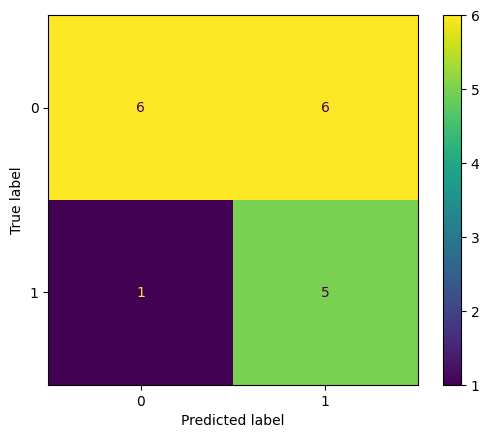

Accuracy: 0.6111111111111112
Precision: 0.7229437229437229
Recall: 0.6111111111111112
F1 Score: 0.6171310629514964


In [ ]:
# 4. IMPLEMENT NAIVE BAYES USING SCIKIT-LEARN

# a) Select numerical features
num_cols = df.drop(columns=['Result']).select_dtypes(include=np.number).columns.tolist()
X = df[num_cols]
y = df['Result']

# b) Split data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

# c) Train Gaussian Naive Bayes
model = GaussianNB()
model.fit(X_train, y_train)

# d) Predict test data
y_pred = model.predict(X_test)

# e) Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()
plt.show()

# f) Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

# g) Confusion Matrix terms
# TP = Correctly predicted Pass
# TN = Correctly predicted Fail
# FP = Actual Fail predicted as Pass
# FN = Actual Pass predicted as Fail

In [ ]:
# 5. CATEGORICAL NAIVE BAYES

# a) Select categorical features
cat_cols = df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist()

X_cat = df[cat_cols]
y = df['Result']

# b) Convert categorical data into numbers
encoder = OrdinalEncoder()
X_cat = encoder.fit_transform(X_cat)

# c) Split data into 70% training and 30% testing
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat, y, test_size=0.3, random_state=42)

# d) Train Categorical Naive Bayes
cat_model = CategoricalNB()
cat_model.fit(X_train_cat, y_train_cat)

# e) Predict test data
cat_pred = cat_model.predict(X_test_cat)

# f) Evaluate model
print("Accuracy:", accuracy_score(y_test_cat, cat_pred))
print("Precision:", precision_score(y_test_cat, cat_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test_cat, cat_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test_cat, cat_pred, average='weighted', zero_division=0))

# g) Compare Gaussian and Categorical Naive Bayes
print("\nGaussian Accuracy:", accuracy_score(y_test, y_pred))
print("Categorical Accuracy:", accuracy_score(y_test_cat, cat_pred))

Accuracy: 0.6111111111111112
Precision: 0.7229437229437229
Recall: 0.6111111111111112
F1 Score: 0.6171310629514964

Gaussian Accuracy: 0.6111111111111112
Categorical Accuracy: 0.6111111111111112


In [ ]:
# 6. NEW PREDICTION

# a) Create three new student records
new_students = X_cat[:3]

# b) Predict Pass or Fail
prediction = cat_model.predict(new_students)

# c) Display predicted class probabilities
probability = cat_model.predict_proba(new_students)

# d) Display results
for i in range(3):
    print("\nStudent", i+1)
    print("Predicted Result:", prediction[i])
    print("Probabilities:", probability[i])


Student 1
Predicted Result: Fail
Probabilities: [0.79940054 0.20059946]

Student 2
Predicted Result: Pass
Probabilities: [0.3095444 0.6904556]

Student 3
Predicted Result: Pass
Probabilities: [0.24349601 0.75650399]


In [ ]:
# NAIVE BAYES

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)


# Mount google drive

drive.mount('/content/drive')

# Load excel dataset

df = pd.read_excel('/content/drive/MyDrive/Naive_Bayes_Dataset.xlsx')

print("Dataset Loaded Successfully!")


# 1. LOAD AND UNDERSTAND THE DATASET

# a) Display first 10 records
print("First 10 Records:")
print(df.head(10))

# b) Display input features and target variable
print("\nInput Features:")
print(df.drop(columns=['Result']).columns.tolist())

print("\nTarget Variable: Result")

# c) Display class distribution
print("\nClass Distribution:")
print(df['Result'].value_counts())

df['Result'].value_counts().plot(kind='bar')
plt.xlabel("Result")
plt.ylabel("Count")
plt.title("Pass and Fail Distribution")
plt.show()

# d) Identify numerical and categorical features
print("\nNumerical Features:")
print(df.drop(columns=['Result']).select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:")
print(df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist())


# 2. BAYES THEOREM AND PROBABILITY CALCULATION

# Select categorical features
cat_cols = df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist()
features = cat_cols[:2]

# a) Calculate prior probability
print("\nPrior Probability:")
print(df['Result'].value_counts(normalize=True))

# b) Calculate conditional probabilities
for col in features:
    print("\n", col)
    print(pd.crosstab(df[col], df['Result'], normalize='columns'))

# c) Naive Bayes assumption
# Features are conditionally independent.

# d) Create a new student
new_student = {col: df[col].mode()[0] for col in features}
print("\nNew Student:", new_student)

# e) Calculate likelihood and posterior
posterior = {}

for c in df['Result'].unique():
    prob = df['Result'].value_counts(normalize=True)[c]

    for col in features:
        count = ((df[col] == new_student[col]) &
                 (df['Result'] == c)).sum()
        total = (df['Result'] == c).sum()
        prob *= count / total

    posterior[c] = prob

# f) Normalize posterior probability
total = sum(posterior.values())

if total > 0:
    posterior = {c: p/total for c, p in posterior.items()}
    print("\nPosterior Probability:", posterior)

    # g) Predict result
    print("Predicted Result:", max(posterior, key=posterior.get))
else:
    print("Zero probability. Apply Laplace smoothing.")


# 3. LAPLACE SMOOTHING AND COMPLETE NAIVE BAYES WORKING

# a) Identify zero probability
# Zero occurs when a feature value is not found in a class.

# b) Apply Laplace smoothing
for col in features:
    print("\nConditional Probability:", col)
    print(pd.crosstab(df[col], df['Result']))

# c) Calculate probability using Laplace smoothing
posterior = {}

for c in df['Result'].unique():
    prob = df['Result'].value_counts()[c] / len(df)

    for col in features:
        count = ((df[col] == new_student[col]) &
                 (df['Result'] == c)).sum()

        k = df[col].nunique()
        total = (df['Result'] == c).sum()

        prob *= (count + 1) / (total + k)

    posterior[c] = prob

# d) Normalize posterior probability
total = sum(posterior.values())
posterior = {c: p/total for c, p in posterior.items()}

print("\nPosterior Probabilities:", posterior)

# e) Predict the result
print("Predicted Result:", max(posterior, key=posterior.get))


# 4. IMPLEMENT NAIVE BAYES USING SCIKIT-LEARN

# a) Select numerical features
num_cols = df.drop(columns=['Result']).select_dtypes(include=np.number).columns.tolist()

X = df[num_cols]
y = df['Result']

# b) Split data into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

# c) Train Gaussian Naive Bayes
model = GaussianNB()
model.fit(X_train, y_train)

# d) Predict test data
y_pred = model.predict(X_test)

# e) Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot()
plt.show()

# f) Calculate evaluation metrics
print("\nGaussian Naive Bayes Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

# g) Confusion Matrix terms
# TP = Correctly predicted Pass
# TN = Correctly predicted Fail
# FP = Actual Fail predicted as Pass
# FN = Actual Pass predicted as Fail


# 5. CATEGORICAL NAIVE BAYES

# a) Select categorical features
cat_cols = df.drop(columns=['Result']).select_dtypes(exclude=np.number).columns.tolist()

X_cat = df[cat_cols]
y = df['Result']

# b) Convert categorical data into numbers
encoder = OrdinalEncoder()
X_cat = encoder.fit_transform(X_cat)

# c) Split data into 70% training and 30% testing
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat, y, test_size=0.3, random_state=42)

# d) Train Categorical Naive Bayes
cat_model = CategoricalNB()
cat_model.fit(X_train_cat, y_train_cat)

# e) Predict test data
cat_pred = cat_model.predict(X_test_cat)

# f) Evaluate model
print("\nCategorical Naive Bayes Evaluation:")
print("Accuracy:", accuracy_score(y_test_cat, cat_pred))
print("Precision:", precision_score(y_test_cat, cat_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test_cat, cat_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test_cat, cat_pred, average='weighted', zero_division=0))

# g) Compare Gaussian and Categorical Naive Bayes
print("\nGaussian Accuracy:", accuracy_score(y_test, y_pred))
print("Categorical Accuracy:", accuracy_score(y_test_cat, cat_pred))


# 6. NEW PREDICTION

# a) Create three new student records
new_students = X_cat[:3]

# b) Predict Pass or Fail
prediction = cat_model.predict(new_students)

# c) Display predicted class probabilities
probability = cat_model.predict_proba(new_students)

# d) Display results
for i in range(3):
    print("\nStudent", i+1)
    print("Predicted Result:", prediction[i])
    print("Probabilities:", probability[i])
